In [4]:
import pandas as pd
from pathlib import Path

repo_folder = Path(
    r"C:\Users\stefa\Desktop\slytherin"
)

data_folder = repo_folder / "Data Cleaning"

# Client-level dataset created from cleaned data
df_v1 = pd.read_csv(
    data_folder / "df_v1.csv"
)

# Web-event dataset
df_web = pd.read_csv(
    data_folder / "df_final_web_data_clean.csv"
)

assert df_v1["client_id"].is_unique
assert df_v1["Variation"].isin(["Test", "Control"]).all()

print("Experiment participants:", len(df_v1))
print("Web events:", len(df_web))

Experiment participants: 50487
Web events: 755405


In [5]:
step_mapping = {
    0: "start",
    1: "step_1",
    2: "step_2",
    3: "step_3",
    4: "confirm"
}

process_steps = [
    "start",
    "step_1",
    "step_2",
    "step_3",
    "confirm"
]

# Keep web events for the final experiment population only
web_analysis = df_web.loc[
    df_web["client_id"].isin(df_v1["client_id"])
].copy()

web_analysis["process_step"] = pd.to_numeric(
    web_analysis["process_step"],
    errors="coerce"
)

web_analysis["step_name"] = (
    web_analysis["process_step"]
    .map(step_mapping)
)

web_analysis = web_analysis.dropna(
    subset=["visit_id", "step_name"]
).copy()

display(
    web_analysis["step_name"]
    .value_counts()
    .reindex(process_steps, fill_value=0)
)

step_name
start      104041
step_1      68410
step_2      56855
step_3      48675
confirm     43214
Name: count, dtype: int64

In [6]:
# Count actions at each process step within each visit
step_counts = (
    web_analysis.groupby(
        ["client_id", "visit_id", "step_name"]
    )
    .size()
    .rename("events_at_step")
    .reset_index()
)

# One row per visit
df_visit_metrics = (
    web_analysis.groupby(["client_id", "visit_id"])
    .agg(
        number_of_events=("step_name", "size"),
        unique_steps=("step_name", "nunique"),
        completed=(
            "step_name",
            lambda steps: steps.eq("confirm").any()
        )
    )
    .reset_index()
)

# Identify repeated steps inside each visit
repeated_step_metrics = (
    step_counts.assign(
        extra_repetitions=step_counts["events_at_step"] - 1
    )
    .groupby(["client_id", "visit_id"])
    .agg(
        repeated_step_events=("extra_repetitions", "sum"),
        has_repeated_step=(
            "extra_repetitions",
            lambda values: (values > 0).any()
        )
    )
    .reset_index()
)

df_visit_metrics = df_visit_metrics.merge(
    repeated_step_metrics,
    on=["client_id", "visit_id"],
    how="left",
    validate="one_to_one"
)

df_visit_metrics["completed"] = (
    df_visit_metrics["completed"].astype(int)
)

display(df_visit_metrics.head())

,client_id,visit_id,number_of_events,unique_steps,completed,repeated_step_events,has_repeated_step
0,555,637149525_38041617439_716659,5,5,1,0,False
1,647,40369564_40101682850_311847,5,5,1,0,False
2,934,7076463_57954418406_971348,4,1,0,3,True
3,1028,557292053_87239438319_391157,9,4,0,5,True
4,1104,543158812_46395476577_767725,1,1,0,0,False


In [22]:
client_friction = (
    df_visit_metrics.groupby("client_id")
    .agg(repeated_step_visits=("has_repeated_step", "sum"))
    .reset_index()
)

df_kpi_clients = (
    df_v1
    .assign(completed_any_visit=lambda df: (df["completed_visits"] > 0).astype(int))
    .merge(
        client_friction,
        on="client_id",
        how="left",
        validate="one_to_one"
    )
)

df_kpi_clients["repeated_step_visits"] = (
    df_kpi_clients["repeated_step_visits"]
    .fillna(0)
    .astype(int)
)

In [23]:
experiment_kpi_summary = (
    df_kpi_clients.groupby("Variation")
    .agg(
        client_count=("client_id", "size"),
        average_visits=("number_of_visits", "mean"),
        median_visits=("number_of_visits", "median"),
        average_events=("number_of_events", "mean"),
        completion_rate=("completed_any_visit", "mean"),
        average_completed_visits=(
            "completed_visits",
            "mean"
        ),
        repeated_step_client_rate=(
            "repeated_step_visits",
            lambda values: (values > 0).mean()
        )
    )
)

percentage_columns = [
    "completion_rate",
    "repeated_step_client_rate"
]

experiment_kpi_summary[percentage_columns] = (
    experiment_kpi_summary[percentage_columns] * 100
)

display(experiment_kpi_summary.round(2))

,client_count,average_visits,median_visits,average_events,completion_rate,average_completed_visits,repeated_step_client_rate
Variation,,,,,,,
Control,23526,1.37,1.0,6.10,65.58,0.68,45.80
Test,26961,1.38,1.0,6.59,69.29,0.81,52.64


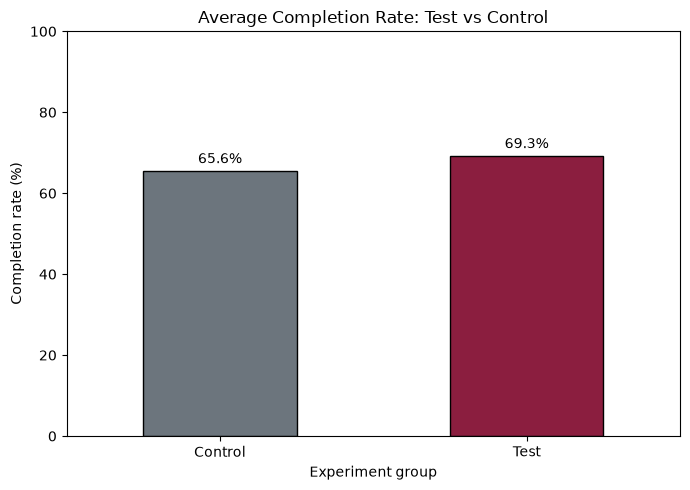

In [9]:
import matplotlib.pyplot as plt

completion_by_group = experiment_kpi_summary["completion_rate"].sort_index()

colors = {
    "Control": "#6C757D",
    "Test": "#8B1E3F"
}

ax = completion_by_group.plot(
    kind="bar",
    color=[colors[group] for group in completion_by_group.index],
    figsize=(7, 5),
    edgecolor="black"
)

ax.set_title("Average Completion Rate: Test vs Control")
ax.set_xlabel("Experiment group")
ax.set_ylabel("Completion rate (%)")
ax.set_ylim(0, 100)

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
average_completion_rate = (df_v1["completed_visits"] > 0).mean() * 100

print(f"Average completion rate: {average_completion_rate:.2f}%")

Average completion rate: 67.56%


In [11]:
completion_rate_by_group = (
    df_v1
    .assign(completed_any_visit=df_v1["completed_visits"] > 0)
    .groupby("Variation")["completed_any_visit"]
    .mean()
    .mul(100)
)

display(completion_rate_by_group.round(2))

Variation
Control    65.58
Test       69.29
Name: completed_any_visit, dtype: float64

In [12]:
import numpy as np
from scipy.stats import norm

# Number of clients who completed at least one visit
test_successes = (df_v1.loc[df_v1["Variation"] == "Test", "completed_visits"] > 0).sum()
control_successes = (df_v1.loc[df_v1["Variation"] == "Control", "completed_visits"] > 0).sum()

# Total clients in each group
test_total = (df_v1["Variation"] == "Test").sum()
control_total = (df_v1["Variation"] == "Control").sum()

# Completion rates
test_rate = test_successes / test_total
control_rate = control_successes / control_total

# Two-proportion z-test: H1 = Test rate > Control rate
pooled_rate = (test_successes + control_successes) / (test_total + control_total)

standard_error = np.sqrt(
    pooled_rate * (1 - pooled_rate) * (1 / test_total + 1 / control_total)
)

z_statistic = (test_rate - control_rate) / standard_error
p_value = norm.sf(z_statistic)  # one-sided: Test > Control

print(f"Test completion rate: {test_rate:.2%}")
print(f"Control completion rate: {control_rate:.2%}")
print(f"Z-statistic: {z_statistic:.3f}")
print(f"P-value: {p_value:.6f}")

Test completion rate: 69.29%
Control completion rate: 65.58%
Z-statistic: 8.893
P-value: 0.000000


In [13]:
# A client completed if they have at least 1 completed visit (or completed_visits > 0)
control_clients = df_v1[df_v1["Variation"] == "Control"]
test_clients = df_v1[df_v1["Variation"] == "Test"]

# Number of successes (completed)
control_successes = (control_clients["completed_visits"] > 0).sum()
test_successes = (test_clients["completed_visits"] > 0).sum()

# Total clients per group
control_total = len(control_clients)
test_total = len(test_clients)

print(
    f"Control: {control_successes}/{control_total} ({control_successes/control_total:.2%})"
)
print(f"Test:    {test_successes}/{test_total} ({test_successes/test_total:.2%})")

Control: 15428/23526 (65.58%)
Test:    18682/26961 (69.29%)


In [14]:
p_value

np.float64(2.9808217938607126e-19)

In [15]:
# Funnel: rate of visits that reached each step
# A visit is counted according to its furthest step reached,
# so backtracking does not remove a completed step.

step_labels = {
    0: "start",
    1: "step_1",
    2: "step_2",
    3: "step_3",
    4: "confirm"
}

# Keep web events only for experiment participants
web_funnel = (
    df_web
    .loc[df_web["client_id"].isin(df_v1["client_id"])]
    .copy()
)

web_funnel["process_step"] = pd.to_numeric(
    web_funnel["process_step"],
    errors="coerce"
)

web_funnel = web_funnel.dropna(
    subset=["client_id", "visit_id", "process_step"]
)

# Add Test / Control label
web_funnel = web_funnel.merge(
    df_v1[["client_id", "Variation"]],
    on="client_id",
    how="left",
    validate="many_to_one"
)

# One row per visit: identify the furthest step reached
visit_progress = (
    web_funnel
    .groupby(["client_id", "visit_id", "Variation"])
    .agg(
        furthest_step=("process_step", "max"),
        started_process=("process_step", lambda steps: (steps == 0).any())
    )
    .reset_index()
)

# Use only visits that recorded a start event
started_visits = visit_progress.loc[
    visit_progress["started_process"]
].copy()

# Calculate the percentage of started visits that reached every step
funnel_results = []

for group in ["Control", "Test"]:
    group_visits = started_visits.loc[
        started_visits["Variation"] == group
    ]

    total_started_visits = len(group_visits)

    for step_number, step_name in step_labels.items():
        reached_step = (group_visits["furthest_step"] >= step_number).sum()

        funnel_results.append({
            "Variation": group,
            "step": step_name,
            "started_visits": total_started_visits,
            "visits_reaching_step": reached_step,
            "step_completion_rate": reached_step / total_started_visits * 100
        })

funnel_results = pd.DataFrame(funnel_results)

funnel_table = (
    funnel_results
    .pivot(
        index="step",
        columns="Variation",
        values="step_completion_rate"
    )
    .reindex(["start", "step_1", "step_2", "step_3", "confirm"])
)

display(funnel_table.round(2))

Variation,Control,Test
step,,
start,100.00,100.00
step_1,75.54,84.70
step_2,64.32,73.01
step_3,57.84,65.41
confirm,48.25,54.07


In [16]:
# Backtracking analysis:
# a backtrack happens when a client goes to a lower step
# after having already reached a higher step in the same visit.

web_sequence = (
    web_funnel
    .merge(
        started_visits[["client_id", "visit_id"]],
        on=["client_id", "visit_id"],
        how="inner",
        validate="many_to_one"
    )
    .copy()
)

web_sequence["date_time"] = pd.to_datetime(
    web_sequence["date_time"],
    errors="coerce"
)

web_sequence = (
    web_sequence
    .dropna(subset=["date_time"])
    .sort_values(
        ["client_id", "visit_id", "date_time"],
        kind="stable"
    )
)

# For every event, find the highest step reached BEFORE that event
web_sequence["highest_previous_step"] = (
    web_sequence
    .groupby(["client_id", "visit_id"])["process_step"]
    .transform(lambda steps: steps.cummax().shift())
)

# True only when the current step is lower than an earlier step
web_sequence["is_backtrack"] = (
    web_sequence["process_step"]
    < web_sequence["highest_previous_step"]
)

# One row per visit
backtracking_by_visit = (
    web_sequence
    .groupby(["client_id", "visit_id", "Variation"])
    .agg(
        has_backtracked=("is_backtrack", "any"),
        number_of_backtracks=("is_backtrack", "sum")
    )
    .reset_index()
)

# Compare Test and Control
backtracking_summary = (
    backtracking_by_visit
    .groupby("Variation")
    .agg(
        total_visits=("visit_id", "size"),
        visits_with_backtracking=("has_backtracked", "sum"),
        average_backtracks_per_visit=("number_of_backtracks", "mean")
    )
)

backtracking_summary["backtracking_rate"] = (
    backtracking_summary["visits_with_backtracking"]
    / backtracking_summary["total_visits"]
    * 100
)

display(backtracking_summary.round(2))

,total_visits,visits_with_backtracking,average_backtracks_per_visit,backtracking_rate
Variation,,,,
Control,30955,6448,0.50,20.83
Test,33206,9900,0.71,29.81


In [17]:
# Identify the direct step-to-step backward transitions
web_sequence["previous_step"] = (
    web_sequence
    .groupby(["client_id", "visit_id"])["process_step"]
    .shift()
)

web_sequence["is_direct_backtrack"] = (
    web_sequence["process_step"] < web_sequence["previous_step"]
)

# Keep only backward movements
backtrack_events = web_sequence.loc[
    web_sequence["is_direct_backtrack"]
].copy()

backtrack_events["from_step"] = (
    backtrack_events["previous_step"]
    .map(step_labels)
)

backtrack_events["backtracked_to_step"] = (
    backtrack_events["process_step"]
    .map(step_labels)
)

# Which step do people return to most often?
backtrack_destination_summary = (
    backtrack_events
    .groupby(["Variation", "backtracked_to_step"])
    .size()
    .reset_index(name="number_of_backtracks")
)

backtrack_destination_summary["percentage_of_backtracks"] = (
    backtrack_destination_summary
    .groupby("Variation")["number_of_backtracks"]
    .transform(lambda values: values / values.sum() * 100)
)

display(
    backtrack_destination_summary
    .sort_values(
        ["Variation", "number_of_backtracks"],
        ascending=[True, False]
    )
    .round(2)
)

,Variation,backtracked_to_step,number_of_backtracks,percentage_of_backtracks
0,Control,start,4809,50.73
2,Control,step_2,2308,24.35
1,Control,step_1,2239,23.62
3,Control,step_3,124,1.31
4,Test,start,10512,65.10
5,Test,step_1,3369,20.86
6,Test,step_2,2241,13.88
7,Test,step_3,25,0.15


In [18]:
backtrack_transition_summary = (
    backtrack_events
    .groupby(["Variation", "from_step", "backtracked_to_step"])
    .size()
    .reset_index(name="number_of_backtracks")
    .sort_values(
        ["Variation", "number_of_backtracks"],
        ascending=[True, False]
    )
)

display(backtrack_transition_summary)

,Variation,from_step,backtracked_to_step,number_of_backtracks
3,Control,step_1,start,2491
8,Control,step_3,step_2,2308
5,Control,step_2,step_1,1356
6,Control,step_3,start,1066
7,Control,step_3,step_1,789
4,Control,step_2,start,772
0,Control,confirm,start,480
2,Control,confirm,step_3,124
1,Control,confirm,step_1,94
13,Test,step_1,start,6402


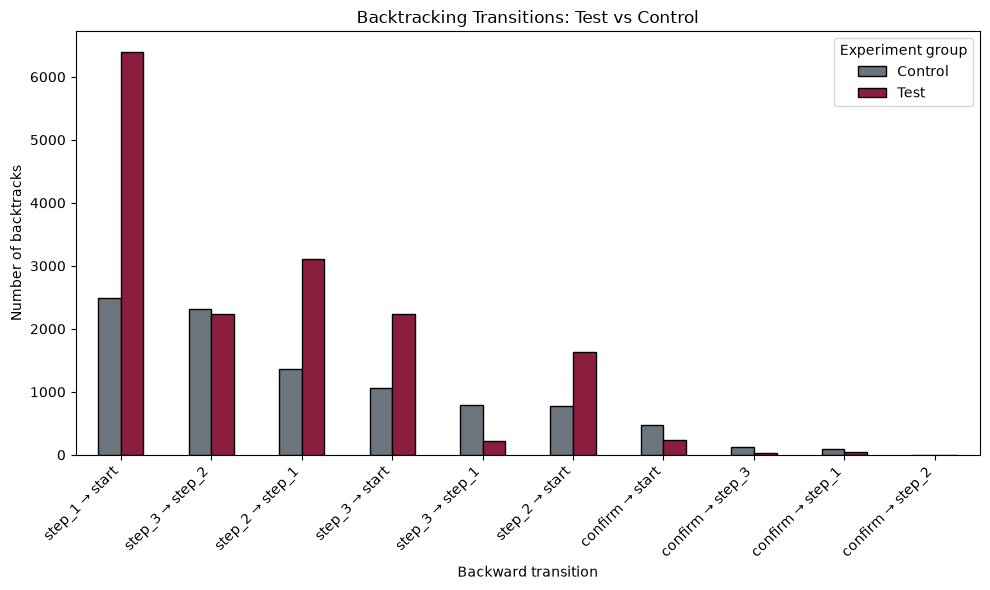

In [19]:
import matplotlib.pyplot as plt

backtrack_transition_summary["transition"] = (
    backtrack_transition_summary["from_step"]
    + " → "
    + backtrack_transition_summary["backtracked_to_step"]
)

transition_chart = (
    backtrack_transition_summary
    .pivot(
        index="transition",
        columns="Variation",
        values="number_of_backtracks"
    )
    .fillna(0)
    .sort_values(
        by=list(backtrack_transition_summary["Variation"].unique()),
        ascending=False
    )
)

ax = transition_chart.plot(
    kind="bar",
    figsize=(10, 6),
    color={"Control": "#6C757D", "Test": "#8B1E3F"},
    edgecolor="black"
)

ax.set_title("Backtracking Transitions: Test vs Control")
ax.set_xlabel("Backward transition")
ax.set_ylabel("Number of backtracks")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Experiment group")
plt.tight_layout()
plt.show()

In [20]:
visit_outcomes = (
    started_visits[["client_id", "visit_id", "Variation"]]
    .merge(
        df_visit_metrics[["client_id", "visit_id", "completed"]],
        on=["client_id", "visit_id"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        backtracking_by_visit[
            ["client_id", "visit_id", "has_backtracked"]
        ],
        on=["client_id", "visit_id"],
        how="left",
        validate="one_to_one"
    )
)

visit_outcomes["has_backtracked"] = (
    visit_outcomes["has_backtracked"]
    .fillna(False)
)

backtracking_completion_comparison = (
    visit_outcomes
    .groupby(["Variation", "has_backtracked"])
    .agg(
        visits=("visit_id", "size"),
        completion_rate=("completed", "mean")
    )
)

backtracking_completion_comparison["completion_rate"] *= 100

display(backtracking_completion_comparison.round(2))

visits  completion_rate
Variation has_backtracked                         
Control   False             24507            47.03
          True               6448            52.88
Test      False             23306            59.13
          True               9900            42.18

In [21]:
from scipy.stats import norm
import numpy as np

backtracking_rate_test = (
    backtracking_by_visit
    .loc[
        backtracking_by_visit["Variation"] == "Test",
        "has_backtracked"
    ]
    .mean()
)

backtracking_rate_control = (
    backtracking_by_visit
    .loc[
        backtracking_by_visit["Variation"] == "Control",
        "has_backtracked"
    ]
    .mean()
)

test_backtracking_visits = (
    backtracking_by_visit
    .loc[
        backtracking_by_visit["Variation"] == "Test",
        "has_backtracked"
    ]
    .sum()
)

control_backtracking_visits = (
    backtracking_by_visit
    .loc[
        backtracking_by_visit["Variation"] == "Control",
        "has_backtracked"
    ]
    .sum()
)

test_visits = (
    backtracking_by_visit["Variation"] == "Test"
).sum()

control_visits = (
    backtracking_by_visit["Variation"] == "Control"
).sum()

pooled_rate = (
    (test_backtracking_visits + control_backtracking_visits)
    / (test_visits + control_visits)
)

standard_error = np.sqrt(
    pooled_rate
    * (1 - pooled_rate)
    * (1 / test_visits + 1 / control_visits)
)

z_statistic = (
    backtracking_rate_test - backtracking_rate_control
) / standard_error

p_value = 2 * norm.sf(abs(z_statistic))

print(f"Test backtracking rate: {backtracking_rate_test:.2%}")
print(f"Control backtracking rate: {backtracking_rate_control:.2%}")
print(f"Difference: {(backtracking_rate_test - backtracking_rate_control):.2%}")
print(f"P-value: {p_value:.6f}")

Test backtracking rate: 29.81%
Control backtracking rate: 20.83%
Difference: 8.98%
P-value: 0.000000
